# 🧭 beyond-automl

> **AutoML finds the best model. LLM + human find the best problem.**

**Result in one line (live run, DeepSeek via OpenRouter):** all 8 problems proposed by the LLM passed the guardrails; the highest-AUC model (annual contract conversion, 0.935) is not the best decision; the recommendation is **overall churn** (AUC 0.845, BRL 10.5M per cycle).

This notebook runs the full experiment step by step:

| Phase | What happens |
| --- | --- |
| 1 · Data | Load IBM Telco Churn and build an aggregated profile (no rows) |
| 2 · LLM Analyst | An LLM (OpenRouter) proposes business problems from the profile |
| 3 · Guardrails | Code validates every suggestion against known generative-AI shortcomings |
| 4 · 20 models | 5 approved problems × 4 algorithms |
| 5 · Technical ranking | AUC, F1, Precision, Recall |
| 6 · Business ranking | Profit-optimal threshold, gain over no model |
| 7 · Recommendation | Best business decision, not best AUC |

The reusable logic lives in `src/beyond_automl/`; this notebook orchestrates it and shows the results.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd() / "src"))
from beyond_automl import business, data, guardrails, llm, modeling

load_dotenv()
pd.set_option("display.max_colwidth", 120)
cfg = yaml.safe_load(open("config.yaml", encoding="utf-8"))
g = cfg["guardrails"]
OUT = Path("results")
OUT.mkdir(exist_ok=True)
t0 = time.time()

## 1 · Data

The dataset is downloaded automatically on the first run. `TotalCharges` is converted to numeric.

In [2]:
df = data.load_data(cfg["data_path"], cfg["data_url"])
ids = data.id_columns(df)
print(f"{len(df):,} customers, {df.shape[1]} columns | ID columns: {ids}")
df.head()

7,043 customers, 21 columns | ID columns: ['customerID']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### What the LLM sees (privacy guardrail)

Only column names, types and aggregated statistics are sent. No customer rows, no IDs.

In [3]:
prof = data.profile(df)
pd.DataFrame(prof["columns"]).fillna("")

C:\Users\doger\AppData\Local\Temp\ipykernel_14752\217395095.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame(prof["columns"]).fillna("")


,name,kind,n_unique,top_values,min,mean,max
0,customerID,id (omitted),,,,,
1,gender,categorical,2.0,"{'Male': 0.505, 'Female': 0.495}",,,
2,SeniorCitizen,categorical,2.0,"{'0': 0.838, '1': 0.162}",,,
3,Partner,categorical,2.0,"{'No': 0.517, 'Yes': 0.483}",,,
4,Dependents,categorical,2.0,"{'No': 0.7, 'Yes': 0.3}",,,
5,tenure,numeric,,,0.0,32.37,72.0
6,PhoneService,categorical,2.0,"{'Yes': 0.903, 'No': 0.097}",,,
7,MultipleLines,categorical,3.0,"{'No': 0.481, 'Yes': 0.422, 'No phone service': 0.097}",,,
8,InternetService,categorical,3.0,"{'Fiber optic': 0.44, 'DSL': 0.344, 'No': 0.217}",,,
9,OnlineSecurity,categorical,3.0,"{'No': 0.497, 'Yes': 0.287, 'No internet service': 0.217}",,,


## 2 · LLM Analyst

The prompt asks for binary-classification problems with a structured target, population, leakage list and BRL assumptions.

In [4]:
print(llm.build_prompt(prof, cfg["llm"]["n_problems"])[-1200:])

    "Bank transfer (automatic)": 0.219,
    "Credit card (automatic)": 0.216
   }
  },
  {
   "name": "MonthlyCharges",
   "kind": "numeric",
   "min": 18.25,
   "mean": 64.76,
   "max": 118.75
  },
  {
   "name": "TotalCharges",
   "kind": "numeric",
   "min": 0.0,
   "mean": 2279.73,
   "max": 8684.8
  },
  {
   "name": "Churn",
   "kind": "categorical",
   "n_unique": 2,
   "top_values": {
    "No": 0.735,
    "Yes": 0.265
   }
  }
 ]
}

Propose 8 business problems that could be modeled as BINARY CLASSIFICATION.
Reply ONLY with valid JSON in this format:
{"problems": [
  {
    "id": "short_snake_case",
    "problem": "short name",
    "objective": "one sentence",
    "target": {"column": "<column>", "operator": "in|not_in|gt|lt", "values": [...]},
    "population": null or {"column": "<column>", "operator": "in|not_in", "values": [...]},
    "leakage_columns": ["columns that must not be used as features"],
    "metric": "AUC|F1|Recall|Precision",
    "value_per_hit_brl": <expected v

In [5]:
resp = llm.ask_llm(prof, cfg["llm"])
print("Source:", resp["source"], "| model:", resp.get("model"))
pd.DataFrame([{
    "id": p["id"], "problem": p["problem"], "target": p["target"]["column"],
    "value/hit (BRL)": p["value_per_hit_brl"], "cost/action (BRL)": p["cost_per_action_brl"],
    "impact (LLM)": p["impact_score"],
} for p in resp["problems"]])

Source: openrouter (live) | model: deepseek/deepseek-v4.1-flash-1017


,id,problem,target,value/hit (BRL),cost/action (BRL),impact (LLM)
0,churn_overall,Overall churn prediction,Churn,1200,50,10
1,churn_month_to_month,Month-to-month churn prediction,Churn,1000,45,9
2,churn_fiber_optic,Fiber optic churn prediction,Churn,1500,60,9
3,contract_conversion,Annual contract conversion targeting,Contract,300,30,7
4,electronic_check_migration,Electronic check migration targeting,PaymentMethod,80,10,6
5,paperless_billing_adoption,Paperless billing adoption targeting,PaperlessBilling,30,5,5
6,tech_support_upsell,Tech support upsell propensity,TechSupport,100,20,6
7,multiple_lines_adoption,Multiple lines adoption propensity,MultipleLines,60,10,5


> Without `OPENROUTER_API_KEY` in `.env`, the notebook uses `problems/llm_problems_cache.json`: an example response written by hand, **on purpose with typical LLM mistakes**, so the guardrails have something to catch.

## 3 · Guardrails: the LLM proposes, the code validates

| Shortcoming | Check |
| --- | --- |
| Hallucinates | Target column and values exist |
| Unreliable | JSON schema + plausible BRL assumptions (≤ 24 months of ARPU) |
| Bias | Sensitive attributes never target nor feature |
| Still learning | Undeclared leakage (single-feature AUC ≥ 0.95) |
| Privacy | Only the aggregated profile goes to the LLM |
| Complexity | Prevalence 3–97%, ≥ 100 positives |

In [6]:
validated = [guardrails.validate_problem(p, df, g, ids) for p in resp["problems"]]
approved = sorted([p for p in validated if p["status"] == "approved"],
                  key=lambda p: -float(p["impact_score"]))[: cfg["max_problems"]]

pd.DataFrame([{"problem": p["problem"], "target": p["target"]["column"], "status": p["status"]}
              for p in validated])

,problem,target,status
0,Overall churn prediction,Churn,approved
1,Month-to-month churn prediction,Churn,approved
2,Fiber optic churn prediction,Churn,approved
3,Annual contract conversion targeting,Contract,approved
4,Electronic check migration targeting,PaymentMethod,approved
5,Paperless billing adoption targeting,PaperlessBilling,approved
6,Tech support upsell propensity,TechSupport,approved
7,Multiple lines adoption propensity,MultipleLines,approved


In [7]:
issues = pd.DataFrame([{"problem": p["problem"], **c} for p in validated for c in p["checks"]])
issues[issues["status"] != "pass"]

,problem,risk,check,status,detail


## 4 · 20 models

5 approved problems × Logistic Regression, Random Forest, XGBoost and LightGBM (stratified 75/25 split, seed 42).

In [8]:
runs = []
for p in approved:
    runs += modeling.run_problem(p, df, cfg["split"])
print(f"{len(runs)} models trained")

auc = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in runs])
auc.pivot(index="problem", columns="model", values="AUC").round(3)

20 models trained


model,LightGBM,LogisticRegression,RandomForest,XGBoost
problem,,,,
Annual contract conversion targeting,0.930,0.935,0.930,0.932
Electronic check migration targeting,0.774,0.779,0.775,0.777
Fiber optic churn prediction,0.771,0.792,0.788,0.782
Month-to-month churn prediction,0.732,0.743,0.741,0.731
Overall churn prediction,0.835,0.845,0.841,0.838


## 5 · Technical ranking

In [9]:
by_id = {p["id"]: p for p in approved}
rows = []
for r in runs:
    p = by_id[r["problem_id"]]
    b = business.score(r, p, cfg["customer_base"], p["n_population"], len(df))
    pred = (r["_proba"] >= b["threshold"]).astype(int)
    gaps = {col: guardrails.recall_gap(r["_y"], pred, df.loc[r["_index"], col])[0]
            for col in g["sensitive_columns"]}
    worst = max(gaps, key=gaps.get)
    rows.append({**{k: v for k, v in r.items() if not k.startswith("_")}, **b,
                 "fairness_gap": gaps[worst], "fairness_attr": worst,
                 "fairness_flag": gaps[worst] > g["fairness_max_recall_gap"],
                 "suspicious_auc": r["AUC"] > g["suspicious_model_auc"]})
lb = pd.DataFrame(rows)
lb.sort_values("AUC", ascending=False)[["problem", "model", "AUC", "F1", "Precision", "Recall"]].head(8).round(3)

,problem,model,AUC,F1,Precision,Recall
12,Annual contract conversion targeting,LogisticRegression,0.935,0.862,0.870,0.854
14,Annual contract conversion targeting,XGBoost,0.932,0.862,0.859,0.865
13,Annual contract conversion targeting,RandomForest,0.930,0.861,0.874,0.847
15,Annual contract conversion targeting,LightGBM,0.930,0.862,0.858,0.866
0,Overall churn prediction,LogisticRegression,0.845,0.623,0.513,0.792
1,Overall churn prediction,RandomForest,0.841,0.634,0.538,0.773
2,Overall churn prediction,XGBoost,0.838,0.555,0.644,0.488
3,Overall churn prediction,LightGBM,0.835,0.575,0.659,0.510


### Post-training guardrail: AUC too good

An AUC close to 1.0 on a business problem is a red flag. A drop-one diagnosis shows which columns almost determine the target, and the problem goes to **human review**.

In [10]:
for pid in lb.loc[lb["suspicious_auc"], "problem_id"].unique():
    p = by_id[pid]
    diag = modeling.leakage_diagnosis(p, df, cfg["split"])
    cols = ", ".join(f"{c} (−{d:.3f} AUC)" for c, d in diag)
    p["checks"].append({
        "risk": "Still learning", "check": "AUC too good (multivariate leakage)", "status": "warn",
        "detail": f"AUC > {g['suspicious_model_auc']}: the target is almost determined by other columns. "
                  f"Strongest dependency: {cols}. Sent to human review.",
    })
    p["status"] = "review"
    print(f"{p['problem']}: {cols}")

lb["status"] = lb["problem_id"].map(lambda i: by_id[i]["status"])
lb["rank_technical"] = lb["AUC"].rank(ascending=False, method="first").astype(int)
lb["rank_business"] = lb["impact_brl"].rank(ascending=False, method="first").astype(int)
lb = lb.sort_values("rank_technical")

## 6 · Business ranking

For each model, the threshold maximizes `profit = TP × value_per_hit − (TP + FP) × cost_per_action`.
Impact = profit − best no-model alternative (act on everyone or no one), extrapolated to 1M customers.

In [11]:
best = (lb.sort_values("impact_brl", ascending=False)
          .groupby("problem_id").head(1)
          .sort_values("impact_brl", ascending=False))
view = best[["problem", "model", "AUC", "impact_brl", "contacted_pct", "precision_at_thr",
             "fairness_attr", "fairness_gap", "status"]].copy()
view["impact_brl"] = (view["impact_brl"] / 1e6).round(1).astype(str) + "M"
view.round(3)

,problem,model,AUC,impact_brl,contacted_pct,precision_at_thr,fairness_attr,fairness_gap,status
0,Overall churn prediction,LogisticRegression,0.845,10.5M,0.722,0.363,gender,0.004,approved
14,Annual contract conversion targeting,XGBoost,0.932,4.6M,0.801,0.681,SeniorCitizen,0.009,approved
8,Fiber optic churn prediction,LogisticRegression,0.792,2.0M,0.924,0.453,gender,0.000,approved
17,Electronic check migration targeting,RandomForest,0.775,1.3M,0.810,0.404,SeniorCitizen,0.011,approved
6,Month-to-month churn prediction,XGBoost,0.731,0.5M,0.979,0.436,gender,0.000,approved


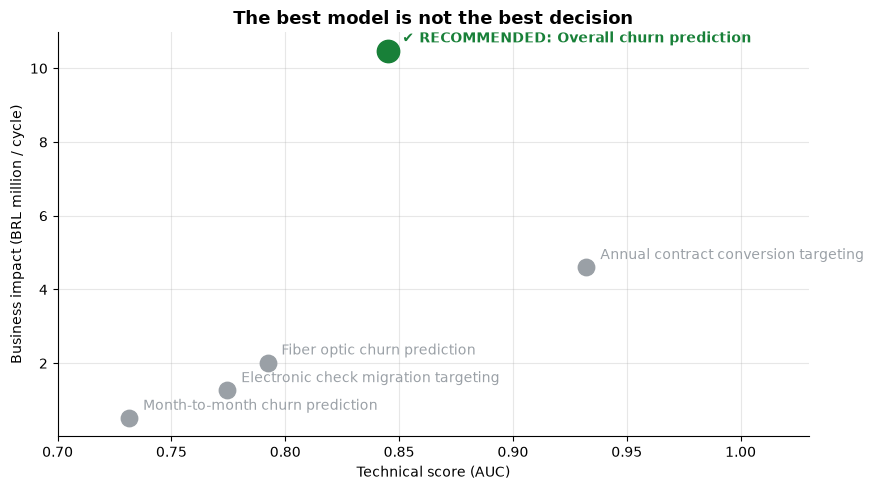

In [12]:
# Hero chart: best model per problem (also saved for the README)
colors = {"approved": "#9aa0a6", "review": "#e8710a"}
fig, ax = plt.subplots(figsize=(9, 5))
for _, r in best.iterrows():
    is_rec = r["problem_id"] == best[best["status"] == "approved"].iloc[0]["problem_id"]
    color = "#188038" if is_rec else colors[r["status"]]
    ax.scatter(r["AUC"], r["impact_brl"] / 1e6, s=260 if is_rec else 140, color=color, zorder=3)
    label = r["problem"]
    if is_rec:
        label = f"✔ RECOMMENDED: {r['problem']}"
    elif r["status"] == "review":
        label = f"⚠ {r['problem']} — leakage, human review"
    ax.annotate(label, (r["AUC"], r["impact_brl"] / 1e6), xytext=(10, 6), textcoords="offset points",
                fontsize=10, color=color, fontweight="bold" if is_rec or r["status"] == "review" else None,
                ha="right" if r["AUC"] > 0.95 else "left")
ax.set_xlabel("Technical score (AUC)")
ax.set_ylabel("Business impact (BRL million / cycle)")
ax.set_title("The best model is not the best decision", fontsize=13, fontweight="bold")
ax.set_xlim(0.70, 1.03)
ax.grid(alpha=0.3)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
Path("assets").mkdir(exist_ok=True)
fig.savefig("assets/auc_vs_impact.png", dpi=150)
plt.show()

## 7 · Recommendation

In [13]:
top_tech = lb.iloc[0]
top_biz = best[best["status"] == "approved"].iloc[0]  # only recommend what passed everything
rec = {
    "recommended_problem": top_biz["problem"], "recommended_model": top_biz["model"],
    "impact_brl": float(top_biz["impact_brl"]), "auc": float(top_biz["AUC"]),
    "best_technical": {"problem": top_tech["problem"], "model": top_tech["model"],
                       "auc": float(top_tech["AUC"]), "impact_brl": float(top_tech["impact_brl"])},
    "same_as_technical": bool(top_tech["problem_id"] == top_biz["problem_id"]),
    "fairness_flag": bool(top_biz["fairness_flag"]),
    "llm": {"source": resp["source"], "model": resp.get("model"), "usage": resp.get("usage")},
    "runtime_s": round(time.time() - t0, 1), "n_models": len(lb),
}
print(f"Recommended: {rec['recommended_problem']} with {rec['recommended_model']} "
      f"— BRL {rec['impact_brl']/1e6:.1f}M per cycle (AUC {rec['auc']:.3f})")
print(f"Best technical: {rec['best_technical']['problem']} (AUC {rec['best_technical']['auc']:.3f}) "
      f"— status: {by_id[top_tech['problem_id']]['status']}")

Recommended: Overall churn prediction with LogisticRegression — BRL 10.5M per cycle (AUC 0.845)
Best technical: Annual contract conversion targeting (AUC 0.935) — status: approved


In [14]:
# Save results for the Streamlit dashboard (streamlit run app.py)
lb.to_csv(OUT / "leaderboard.csv", index=False)
best.to_csv(OUT / "business_ranking.csv", index=False)
json.dump(validated, open(OUT / "problems_validated.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=2, default=str)
json.dump(rec, open(OUT / "recommendation.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Saved to", OUT.resolve().name + "/")

Saved to results/


## Takeaways

- The **highest AUC** came from a problem whose target is almost a deterministic function of other columns: a leak, caught by code, not by the LLM.
- The **recommended** problem has a lower AUC but the largest business gain.
- The LLM is useful for **framing problems**, but every suggestion needs validation: it can invent columns, propose implausible values and ignore bias.

**Limitations (MVP):** threshold optimized on the test set (optimistic); targets are "who already has X" (propensity proxy); `MonthlyCharges` treated as BRL.